<a href="https://colab.research.google.com/github/ananyamatta1112-crypto/Solar-Limb-Darkening-/blob/main/solar_limb_darkening.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install --upgrade numpy


In [ ]:
!pip install rawpy imageio

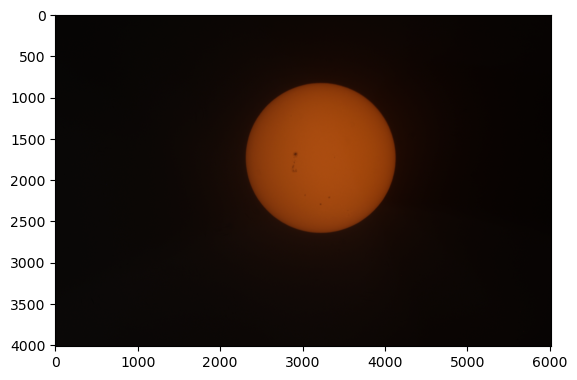

In [ ]:
#0
import rawpy
import matplotlib.pyplot as plt
import numpy as np

img = "/Users/adityamaheshnagare/Downloads/DSC_0417.NEF"
with rawpy.imread(img) as raw:
    rgb = raw.postprocess(
        #demosaic_algorithm=rawpy.DemosaicAlgorithm.AHD, #Adaptive Homogeneity-Directed demosaicing algorithm for better image quality
        use_camera_wb=True, #white balance based on camera settings to avoid color cast(sun appearing too yellow/blue)
        no_auto_bright=True,
        output_bps=8,
    ) #converts raw sensor data to RGB image
plt.imshow(rgb) # to render processed RGB image from numpy array

In [ ]:
# #1- demosaicing.
# import rawpy
# import matplotlib.pyplot as plt
# import numpy as np

# img = "/Users/adityamaheshnagare/Downloads/DSC_0417.NEF"
# with rawpy.imread(img) as raw:
#     rgb = raw.postprocess(
#         demosaic_algorithm=rawpy.DemosaicAlgorithm.AHD, #Adaptive Homogeneity-Directed demosaicing algorithm for better image quality
#         use_camera_wb=True, #white balance based on camera settings to avoid color cast(sun appearing too yellow/blue)
#         no_auto_bright=True,
#         output_bps=8,
#     ) #converts raw sensor data to RGB image
# plt.imshow(rgb) # to render processed RGB image from numpy array

# #inference: Not much of a difference

In [ ]:
# import rawpy
# import matplotlib.pyplot as plt
# import numpy as np

# img = "/Users/adityamaheshnagare/Downloads/DSC_0417.NEF"
# with rawpy.imread(img) as raw:
#     rgb = raw.postprocess(
#         demosaic_algorithm=rawpy.DemosaicAlgorithm.AHD, #Adaptive Homogeneity-Directed demosaicing algorithm for better image quality
#         use_camera_wb=True, #white balance based on camera settings to avoid color cast(sun appearing too yellow/blue)
#         no_auto_bright=True,
#         output_color=rawpy.ColorSpace.raw, #to preserve original colors without camera color profile adjustments
#         output_bps=8,
#     ) #converts raw sensor data to RGB image
# plt.imshow(rgb) # to render processed RGB image from numpy array

In [ ]:
# with rawpy.imread(img) as raw:
#     rgb = raw.postprocess(
#         demosaic_algorithm=rawpy.DemosaicAlgorithm.AHD, #Adaptive Homogeneity-Directed demosaicing algorithm for better image quality
#         use_camera_wb=True, #white balance based on camera settings to avoid color cast(sun appearing too yellow/blue)
#         no_auto_bright=True,
#         output_color=rawpy.ColorSpace.raw,
#         gamma=(1, 1), #to preserve original colors without camera color profile adjustments
#         output_bps=8,
#     ) #converts raw sensor data to RGB image
# plt.imshow(rgb)

Text(0.5, 1.0, 'Blue Channel')

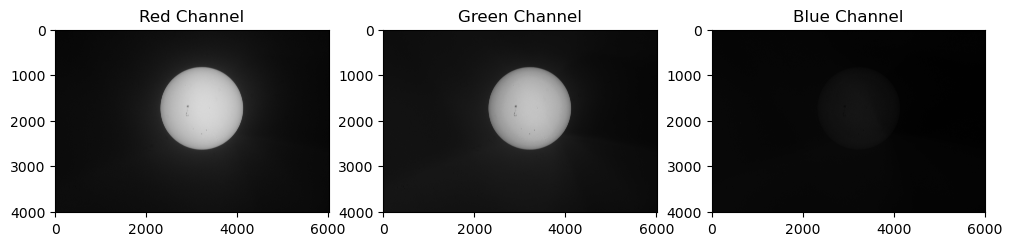

In [ ]:
rgb=rgb.astype(np.float32)
R=rgb[:, :, 0]
G=rgb[:, :, 1]
B=rgb[:, :, 2]

plt.figure(figsize=(12, 8))
plt.subplot(1,3,1)
plt.imshow(R, cmap='gray')
plt.title('Red Channel')

plt.subplot(1,3,2)
plt.imshow(G, cmap='gray')
plt.title('Green Channel')

plt.subplot(1,3,3)
plt.imshow(B, cmap='gray')
plt.title('Blue Channel')

In [ ]:
# R_log=np.log1p(R) #log transformation to enhance details in darker areas; log(1 + R)
# G_log=np.log1p(G)
# B_log=np.log1p(B)

# Rn_log=np.uint8(255 * (R_log / np.max(R_log))) #normalize to 0-255 range for display
# Gn_log=np.uint8(255 * (G_log / np.max(G_log)))
# Bn_log=np.uint8(255 * (B_log / np.max(B_log)))
# #uint8- positive whole nos. of 8 bits(0-255 )

# rgb_log= np.stack([Rn_log, Gn_log, Bn_log], axis=-1) #or axis=2; basically we stack the log transformed channels along the last axis.

# plt.imshow(rgb_log)
# plt.axis('off')
# plt.title('Log Transformed RGB Image')

In [ ]:
# r1=rgb_log[:, :, 0]
# g1=rgb_log[:, :, 1]
# b1=rgb_log[:, :, 2]

# plt.figure(figsize=(12, 8))
# plt.subplot(1,3,1)
# plt.imshow(r1, cmap='gray')
# plt.title('Red Channel')

# plt.subplot(1,3,2)
# plt.imshow(g1, cmap='gray')
# plt.title('Green Channel')

# plt.subplot(1,3,3)
# plt.imshow(b1, cmap='gray')
# plt.title('Blue Channel')

#fig,axes = plt.subplots(1,3,figsize=(15,5))
#axes[0].imshow(light_r,origin='lower',cmap='grey')
#axes[1].imshow(light_g,origin='lower',cmap='grey')
#axes[2].imshow(light_b,origin='lower',cmap='grey')
#axes[0].set_title('Red Channel')
#axes[1].set_title('Green Channel')
#axes[2].set_title('Blue Channel')
#plt.show()

In [ ]:
import glob
import os

def load_nef_stack(folder_path):
    """Load NEF files and return stacked GREEN channel images (half-res)."""
    files = sorted(glob.glob(folder_path + "/*.[Nn][Ee][Ff]"))
    images = []

    for f in files:
        with rawpy.imread(f) as raw:
            full = raw.raw_image.astype(np.float64)
            # Extract G1 and G2 from RGGB Bayer pattern and average
            G1 = full[0::2, 1::2]
            G2 = full[1::2, 0::2]
            images.append(0.5 * (G1 + G2))

    return np.stack(images)


In [ ]:
dark_stack= load_nef_stack("/Users/adityamaheshnagare/Desktop/solarlimb/Darkframes")
flat_stack = load_nef_stack("/Users/adityamaheshnagare/Desktop/solarlimb/flats")
flat_dark_stack = load_nef_stack("/Users/adityamaheshnagare/Desktop/solarlimb/flatdarks")
#each stack shape: (num_images, height, width)

In [ ]:
import glob

glob.glob("/Users/adityamaheshnagare/Downloads/darks/*.NEF")

[]

In [ ]:
#median stacking for master frames
master_dark = np.median(dark_stack, axis=0)
master_flat_dark = np.median(flat_dark_stack, axis=0)
master_flat_raw = np.median(flat_stack, axis=0)

In [ ]:
# [Superseded] First naive flat normalisation – the robust pipeline
# below (flat_corrected with NaN handling + clipping) overrides this.
# master_flat = master_flat_raw - master_flat_dark
# master_flat /= np.median(master_flat)


In [ ]:
# [Duplicate] master_flat_dark and master_flat_raw already computed
# in the median stacking cell above – no need to recompute.
# master_flat_dark = np.median(flat_dark_stack, axis=0)
# master_flat_raw  = np.median(flat_stack, axis=0)


In [ ]:
flat_corrected = master_flat_raw - master_flat_dark
master_flat = flat_corrected / np.median(flat_corrected)

In [ ]:
print(master_flat.min(), master_flat.max())
#flat_dark > flat

0.051931251155054516 1.3564960266124562


In [ ]:
flat_corrected[flat_corrected <= 0] = np.nan
norm_factor = np.nanmedian(flat_corrected)
master_flat = flat_corrected / norm_factor

In [ ]:
print(np.nanmin(master_flat), np.nanmax(master_flat))

0.051931251155054516 1.3564960266124562


In [ ]:
master_flat = np.clip(master_flat, 0.5, 1.5)

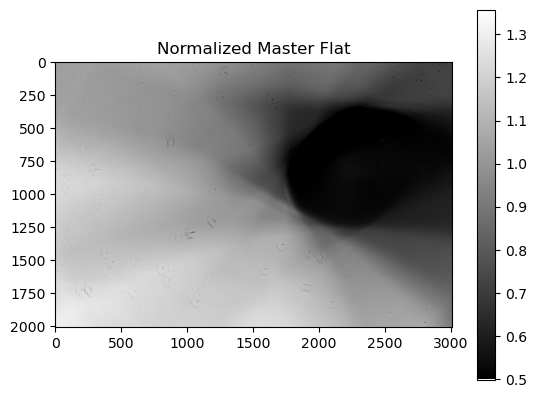

In [ ]:
import matplotlib.pyplot as plt

plt.imshow(master_flat, cmap='gray')
plt.colorbar()
plt.title("Normalized Master Flat")
plt.show()

In [ ]:
with rawpy.imread(img) as raw:
    full_raw   = raw.raw_image.astype(np.float64)
    bayer_desc = raw.color_desc.decode()   # e.g. b'RGBG' or b'RGGB'
    color_mask = raw.raw_colors            # per-pixel colour index (0=R,1=G,2=B,3=G2)

# Nikon DSLRs use RGGB pattern:
#   row even, col even  → R
#   row even, col odd   → G1
#   row odd,  col even  → G2
#   row odd,  col odd   → B
# Extract G1 (top-left green of each 2x2 block) → half-resolution green image
print(f"Bayer pattern: {bayer_desc}")

# Build a boolean mask for ALL green pixels (indices 1 and 3 in RGBG/RGGB)
green_mask = (color_mask == 1) | (color_mask == 3)

# Green sub-image at half resolution using G1 (even row, odd col in RGGB)
# Both G channels are extracted and averaged per 2x2 block for better SNR
h, w = full_raw.shape
# G1: [0::2, 1::2],  G2: [1::2, 0::2]  for RGGB
G1 = full_raw[0::2, 1::2]
G2 = full_raw[1::2, 0::2]
solar_raw = 0.5 * (G1 + G2)   # average both greens → half-res green image

print(f"Full raw shape : {full_raw.shape}")
print(f"Green image shape: {solar_raw.shape}")


Bayer pattern: RGBG
Full raw shape : (4016, 6016)
Green image shape: (2008, 3008)


In [ ]:
solar_raw.shape

(2008, 3008)

In [ ]:
# Duplicate of the cell above – commented out to avoid redundant file read.
# with rawpy.imread(img) as raw:
#     solar_raw = raw.raw_image.astype(np.float64)


In [ ]:
# Subtract dark and divide by normalised flat for proper calibration
solar_cal_raw = (solar_raw - master_dark)
solar_cal_raw[solar_cal_raw <= 0] = np.nan


In [ ]:
#optional reconstruction
#with rawpy.imread(img) as raw:
 #   raw.raw_image[:] = np.nan_to_num(solar_cal_raw, nan=0)

#    rgb = raw.postprocess(
 #       demosaic_algorithm=rawpy.DemosaicAlgorithm.AHD,
  #      use_camera_wb=True,
   #     no_auto_bright=True,
    #    gamma=(1, 1),
     #   output_bps=8
    #)

#plt.imshow(rgb)

In [ ]:
#limb-edge smoothing
from scipy.ndimage import gaussian_filter
from scipy.optimize import curve_fit
smooth = gaussian_filter(solar_cal_raw, sigma=2)

In [ ]:
gy, gx = np.gradient(smooth) #rate of change of pixel intensities in x,y directions
grad_mag = np.sqrt(gx**2 + gy**2) #combining both directions into a single scalar value.

In [ ]:
#99 % : as percentile for all the pixels.
threshold = np.nanpercentile(grad_mag, 99)
limb_mask = grad_mag > threshold


In [ ]:
# plt.imshow(smooth[limb_mask], origin="lower", cmap="gray")

In [ ]:
y, x = np.where(limb_mask)

In [ ]:
!pip install photutils

In [ ]:
import numpy as np

def intensity_centroid(image):
    image = image - np.min(image)   # ensure non-negative
    y, x = np.indices(image.shape)
    total = np.sum(image)
    xc = np.sum(x * image) / total
    yc = np.sum(y * image) / total
    return xc, yc

xc, yc = intensity_centroid(smooth)


In [ ]:
r = np.sqrt((x - xc)**2 + (y - yc)**2)
r = np.median(r)


In [ ]:
# import matplotlib.pyplot as plt

# plt.imshow(smooth, cmap="gray")
# theta = np.linspace(0, 2*np.pi, 500)
# plt.plot(xc + r*np.cos(theta), yc + r*np.sin(theta), 'r', lw=2)
# plt.scatter(xc, yc, c='blue', s=30)
# plt.title("Solar Disk Fit")
# plt.axis("off")
# plt.show()


Center: (1586.7, 870.7), Radius: 453.7


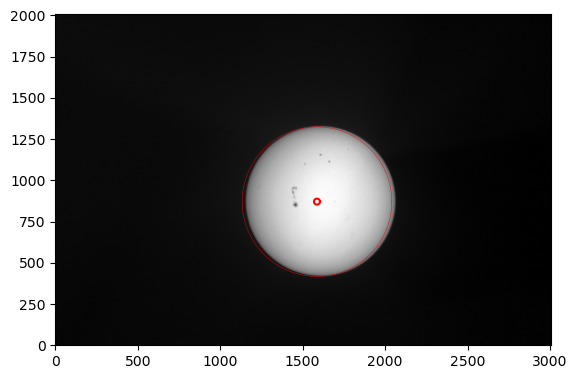

In [ ]:
yy, xx = np.indices(smooth.shape)

# Rough center estimate
xc0 = np.median(xx[limb_mask])
yc0 = np.median(yy[limb_mask])

rr0 = np.sqrt((xx - xc0)**2 + (yy - yc0)**2)

r_estimate = np.median(rr0[limb_mask])
limb = limb_mask & (np.abs(rr0 - r_estimate) < 200)

x = xx[limb]
y = yy[limb]

#using algebraic distance minimization method to fit circle to points: median based
def fit_circle(x, y):
    x_m = np.median(x)
    y_m = np.median(y)

    u = x - x_m
    v = y - y_m

    Suu = np.sum(u*u)
    Suv = np.sum(u*v)
    Svv = np.sum(v*v)
    Suuu = np.sum(u*u*u)
    Svvv = np.sum(v*v*v)
    Suvv = np.sum(u*v*v)
    Svuu = np.sum(v*u*u)

    A = np.array([[Suu, Suv],
                  [Suv, Svv]])
    B = np.array([(Suuu + Suvv)/2,
                  (Svvv + Svuu)/2])

    uc, vc = np.linalg.solve(A, B)

    xc = x_m + uc
    yc = y_m + vc
    r = np.sqrt(uc**2 + vc**2 + (Suu + Svv)/len(x))

    return xc, yc, r

xc, yc, r = fit_circle(x, y)

print(f"Center: ({xc:.1f}, {yc:.1f}), Radius: {r:.1f}")

##visualizing the fit

theta = np.linspace(0, 2*np.pi, 400)

plt.imshow(smooth, origin="lower", cmap="gray")
plt.plot(xc + r*np.cos(theta), yc + r*np.sin(theta), 'r',lw=0.3)
plt.plot(xc + 0.04*r*np.cos(theta), yc + 0.04*r*np.sin(theta), 'r') #centroid used later in normalizing intensity.
plt.show()

Center: (1610.2, 868.6), Radius: 447.8


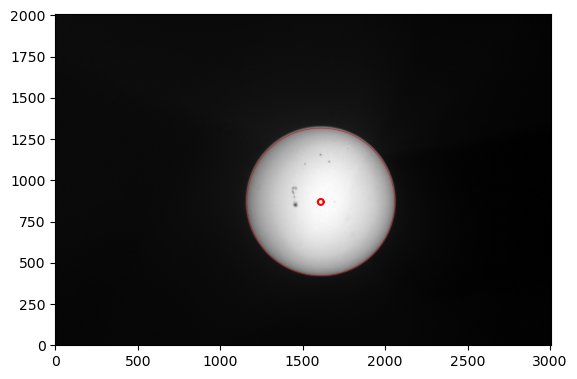

In [ ]:
yy, xx = np.indices(smooth.shape)

# Rough center estimate
xc0 = np.median(xx[limb_mask])
yc0 = np.median(yy[limb_mask])

rr0 = np.sqrt((xx - xc0)**2 + (yy - yc0)**2)

r_estimate = np.median(rr0[limb_mask])
limb = limb_mask & (np.abs(rr0 - r_estimate) < 200)

x = xx[limb]
y = yy[limb]

#using algebraic distance minimization method to fit circle to points: mean based (better for this case)
def fit_circle(x, y):
    x_m = np.mean(x)
    y_m = np.mean(y)

    u = x - x_m
    v = y - y_m

    Suu = np.sum(u*u)
    Suv = np.sum(u*v)
    Svv = np.sum(v*v)
    Suuu = np.sum(u*u*u)
    Svvv = np.sum(v*v*v)
    Suvv = np.sum(u*v*v)
    Svuu = np.sum(v*u*u)

    A = np.array([[Suu, Suv],
                  [Suv, Svv]])
    B = np.array([(Suuu + Suvv)/2,
                  (Svvv + Svuu)/2])

    uc, vc = np.linalg.solve(A, B)

    xc = x_m + uc
    yc = y_m + vc
    r = np.sqrt(uc**2 + vc**2 + (Suu + Svv)/len(x))

    return xc, yc, r

xc, yc, r = fit_circle(x, y)

print(f"Center: ({xc:.1f}, {yc:.1f}), Radius: {r:.1f}")

##visualizing the fit

theta = np.linspace(0, 2*np.pi, 500)

plt.imshow(smooth, origin="lower", cmap="gray")
plt.plot(xc + r*np.cos(theta), yc + r*np.sin(theta), 'r',lw=0.3)
plt.plot(xc + 0.04*r*np.cos(theta), yc + 0.04*r*np.sin(theta), 'r') #centroid used later in normalizing intensity.
plt.show()

In [ ]:
# NOTE: rr and disk_mask are computed in the next cell.
# R_sun is also set there from the circle fit. This cell is superseded.
# R_sun = np.mean(rr[disk_mask & limb_mask])
# print('Solar radius (pixels):', R_sun, type(R_sun))


In [ ]:
rr = np.sqrt((xx - xc)**2 + (yy - yc)**2)
# Use the fitted circle radius `r` as the solar radius
R_sun = float(r)  # r comes from fit_circle(); renamed to R_sun for clarity
disk_mask = rr <= R_sun

n_annuli = 50
edges = np.linspace(0, R_sun, n_annuli + 1)


In [ ]:
rr = np.sqrt((xx - xc)**2 + (yy - yc)**2)
disk_mask = rr <= R_sun

n_annuli = 50
edges = np.linspace(0, R_sun, n_annuli + 1)

mu_vals = []
I_mean  = []
I_std   = []
r_mean  = []

# Robust I0: median over central 2% of solar radius
core_mask = rr <= 0.02 * R_sun
I0 = float(np.nanmedian(solar_cal_raw[core_mask]))
print(f"I0 = {I0:.2f}")

for i in range(n_annuli):
    annulus_mask = (rr >= edges[i]) & (rr < edges[i+1]) & disk_mask
    if np.sum(annulus_mask) == 0:
        continue

    valid = solar_cal_raw[annulus_mask]
    valid = valid[np.isfinite(valid)]
    if len(valid) < 5:
        continue

    r_mid  = 0.5 * (edges[i] + edges[i+1])
    mu_mid = np.sqrt(max(0.0, 1.0 - (r_mid / R_sun)**2))

    r_mean.append(r_mid)
    I_mean.append(np.median(valid))
    I_std.append(np.std(valid))      # natural scatter within the annulus
    mu_vals.append(mu_mid)

mu_vals = np.array(mu_vals)
I_mean  = np.array(I_mean)
I_std   = np.array(I_std)
r_mean  = np.array(r_mean)
r_norm  = r_mean / R_sun

I_norm  = I_mean / I0
I_err   = I_std  / I0   # normalised scatter — used as error bars


I0 = 1662.00


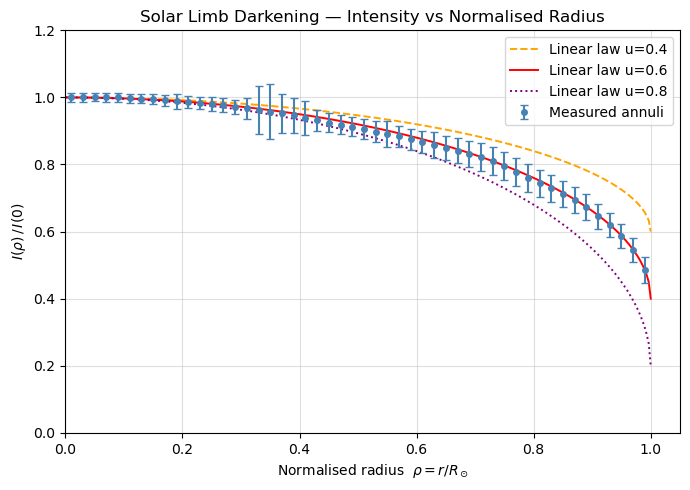

In [ ]:
# ── Plot 1: Normalised Intensity vs Normalised Radius ──────────────────────
fig, ax = plt.subplots(figsize=(7, 5))

ax.errorbar(r_norm, I_norm, yerr=I_err,
            fmt='o', ms=4, capsize=3, color='steelblue',
            label='Measured annuli', zorder=3)

# Overplot linear limb-darkening curves in r-space for reference
#   mu = sqrt(1 - rho^2)  =>  I/I0 = 1 - u*(1 - sqrt(1-rho^2))
rho = np.linspace(0, 1, 300)
mu_rho = np.sqrt(np.maximum(0, 1 - rho**2))
for u_ref, ls, col in zip([0.4, 0.6, 0.8],
                           ['--', '-', ':'],
                           ['orange', 'red', 'purple']):
    ax.plot(rho, 1 - u_ref*(1 - mu_rho), ls, lw=1.4, color=col,
            label=f'Linear law u={u_ref}')

ax.set_xlabel(r"Normalised radius  $\rho = r/R_\odot$")
ax.set_ylabel(r"$I(\rho)\,/\,I(0)$")
ax.set_title("Solar Limb Darkening — Intensity vs Normalised Radius")
ax.set_xlim(0, 1.05)
ax.set_ylim(0, 1.2)
ax.legend()
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


In [ ]:
print(mu_vals.shape)
print(I_norm.shape)

(50,)
(50,)


In [ ]:
mu_vals

array([0.99995   , 0.9995499 , 0.99874922, 0.99754699, 0.99594177,
       0.99393159, 0.99151399, 0.988686  , 0.98544406, 0.98178409,
       0.97770139, 0.97319063, 0.96824584, 0.96286032, 0.95702665,
       0.95073656, 0.94398093, 0.9367497 , 0.92903175, 0.92081486,
       0.91208552, 0.90282889, 0.89302855, 0.88266641, 0.87172243,
       0.8601744 , 0.84799764, 0.83516465, 0.82164469, 0.80740324,
       0.79240141, 0.77659513, 0.75993421, 0.7423611 , 0.72380937,
       0.70420168, 0.68344714, 0.66143783, 0.63804389, 0.61310684,
       0.58642988, 0.55776339, 0.52678269, 0.49305172, 0.45596052,
       0.41460825, 0.36755952, 0.3122499 , 0.24310492, 0.14106736])

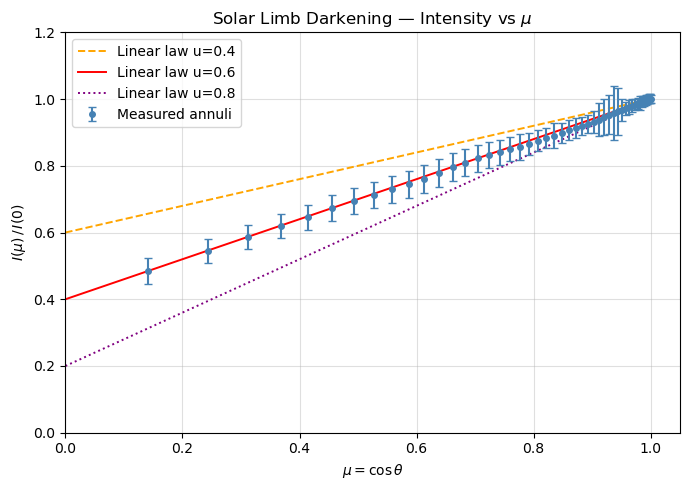

In [ ]:
# Plot 2: Normalised Intensity vs mu = cos(theta)
fig, ax = plt.subplots(figsize=(7, 5))

ax.errorbar(mu_vals, I_norm, yerr=I_err,
            fmt='o', ms=4, capsize=3, color='steelblue',
            label='Measured annuli', zorder=3)

mu_theory = np.linspace(0, 1, 300)
for u_ref, ls, col in zip([0.4, 0.6, 0.8],
                           ['--', '-', ':'],
                           ['orange', 'red', 'purple']):
    ax.plot(mu_theory, 1 - u_ref*(1 - mu_theory), ls, lw=1.4, color=col,
            label=f'Linear law u={u_ref}')

ax.set_xlabel(r"$\mu = \cos\theta$")
ax.set_ylabel(r"$I(\mu)\,/\,I(0)$")
ax.set_title("Solar Limb Darkening — Intensity vs $\mu$")
ax.set_xlim(0, 1.05)
ax.set_ylim(0, 1.2)
ax.legend()
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


Linear limb darkening coefficient  u = 0.609 ± 0.017
(Solar literature: u ≈ 0.60–0.87 depending on wavelength band)


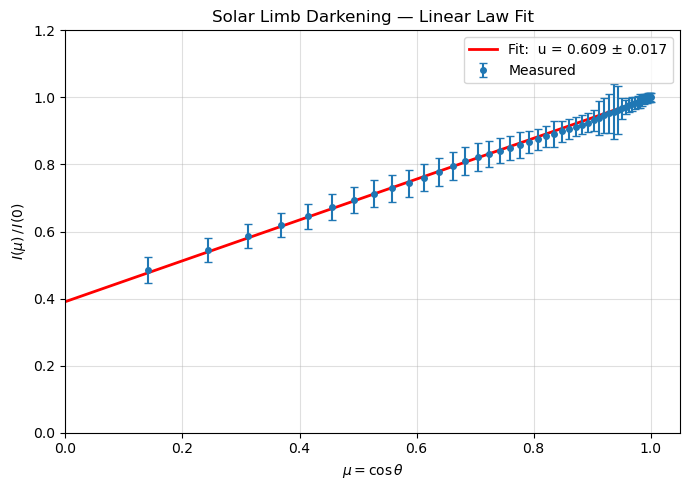

In [ ]:
import numpy as np
from scipy.optimize import curve_fit

def linear_limb_darkening(mu, u):
    """I(mu)/I(0) = 1 - u*(1 - mu),  physically 0 < u < 1 for the Sun"""
    return 1 - u * (1 - mu)

# Use the physical error budget computed in the photometry cell
sigma = np.where(I_err > 0, I_err, 1e-6)   # guard against exact zeros

popt, pcov = curve_fit(
    linear_limb_darkening,
    mu_vals,
    I_norm,
    p0=[0.6],
    bounds=(0.0, 1.0),
    sigma=sigma,
    absolute_sigma=True
)

u_nu  = popt[0]
u_err = np.sqrt(np.diag(pcov))[0]

print(f"Linear limb darkening coefficient  u = {u_nu:.3f} ± {u_err:.3f}")
print(f"(Solar literature: u ≈ 0.60–0.87 depending on wavelength band)")

# Plot fit
mu_fit = np.linspace(0, 1, 300)
fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(mu_vals, I_norm, yerr=I_err, fmt='o', ms=4,
            capsize=3, label='Measured', zorder=3)
ax.plot(mu_fit, linear_limb_darkening(mu_fit, u_nu), 'r-', lw=2,
        label=f'Fit:  u = {u_nu:.3f} ± {u_err:.3f}')
ax.set_xlabel(r"$\mu = \cos\theta$")
ax.set_ylabel(r"$I(\mu)\,/\,I(0)$")
ax.set_title("Solar Limb Darkening — Linear Law Fit")
ax.set_xlim(0, 1.05)
ax.set_ylim(0, 1.2)
ax.legend()
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


Text(0.5, 1.0, 'Log Transformed RGB Image')

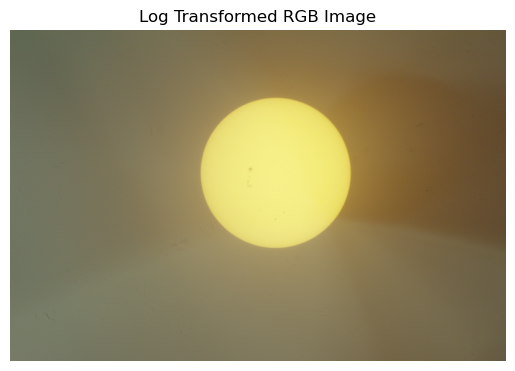

In [ ]:
#Extra visualisation tasks
R_log=np.log1p(R) #log transformation to enhance details in darker areas; log(1 + R)
G_log=np.log1p(G)
B_log=np.log1p(B)

Rn_log=np.uint8(255 * (R_log / np.max(R_log))) #normalize to 0-255 range for display
Gn_log=np.uint8(255 * (G_log / np.max(G_log)))
Bn_log=np.uint8(255 * (B_log / np.max(B_log)))
#uint8- positive whole nos. of 8 bits(0-255 )

rgb_log= np.stack([Rn_log, Gn_log, Bn_log], axis=-1) #or axis=2; basically we stack the log transformed channels along the last axis.

plt.imshow(rgb_log)
plt.axis('off')
plt.title('Log Transformed RGB Image')

Text(0.5, 1.0, 'Blue Channel')

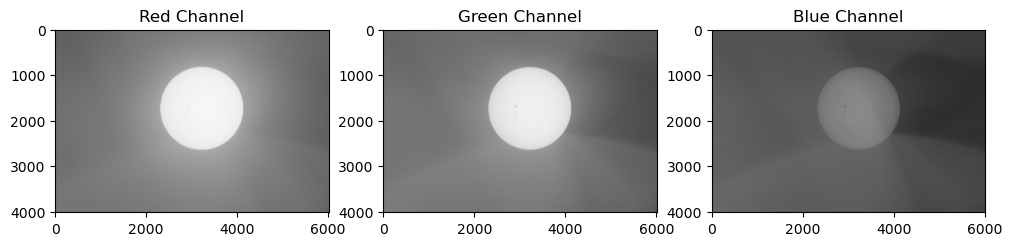

In [ ]:
r1=rgb_log[:, :, 0]
g1=rgb_log[:, :, 1]
b1=rgb_log[:, :, 2]

plt.figure(figsize=(12, 8))
plt.subplot(1,3,1)
plt.imshow(r1, cmap='gray')
plt.title('Red Channel')

plt.subplot(1,3,2)
plt.imshow(g1, cmap='gray')
plt.title('Green Channel')

plt.subplot(1,3,3)
plt.imshow(b1, cmap='gray')
plt.title('Blue Channel')

# fig,axes = plt.subplots(1,3,figsize=(15,5))
# axes[0].imshow(light_r,origin='lower',cmap='grey')
# axes[1].imshow(light_g,origin='lower',cmap='grey')
# axes[2].imshow(light_b,origin='lower',cmap='grey')
# axes[0].set_title('Red Channel')
# axes[1].set_title('Green Channel')
# axes[2].set_title('Blue Channel')
# plt.show()